# Question-2: CycleGAN for Person Face Sketches
Unpaired photo ↔ sketch translation (Zhu et al., 2017), trained end-to-end on
[Person Face Sketches](https://www.kaggle.com/datasets/almightyj/person-face-sketches).

**Runtime → Change runtime type → GPU.** Checkpoints go to Google Drive. After a disconnect, run the cells again from the top and training picks up from the last saved epoch.

**Submitting:** the graded record is this notebook *with its outputs*. In Colab, open Edit → Notebook settings and make sure "Omit code cell output when saving" is **off**. When everything has run, use File → Download → .ipynb and replace `colab_run.ipynb` in the repo with it. Training logs are also written to Drive, and the *Full log* cells below print them into the notebook, so a run split across several sessions still appears in full.

**Run all:** Runtime → Run all runs the whole notebook start to finish, in about 2–3.5 hours on a T4. The only interaction is the Google Drive permission popup at the start, and allowing the file download at the end. Keep the tab open while it runs. If a step fails, the cell right after it stops with a message saying which step.

In [1]:
from google.colab import drive, userdata
drive.mount('/content/drive')
!git clone https://github.com/uShaukat3737/genAiA2.git /content/drive/MyDrive/as2

Mounted at /content/drive
fatal: destination path '/content/drive/MyDrive/as2' already exists and is not an empty directory.


## 1. GPU check

In [2]:
!nvidia-smi
import torch; print(torch.__version__, torch.cuda.is_available())
assert torch.cuda.is_available(), "No GPU: Runtime -> Change runtime type -> T4 GPU, then Run all again"

Mon Oct 12 14:02:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   57C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Drive + code
Upload this `q2/` folder to `MyDrive/as2/q2` first. If you use a different location, change `CODE_DIR`.

Each script's console output is also appended to `cyclegan_ckpt/logs/<step>.log` on Drive, so it survives a disconnect.

In [3]:
from google.colab import drive; drive.mount('/content/drive')
CODE_DIR = '/content/drive/MyDrive/as2/q2'
CKPT = '/content/drive/MyDrive/cyclegan_ckpt'
%cd $CODE_DIR
!pip -q install -r requirements.txt
!mkdir -p "$CKPT/logs"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/as2/q2


## 3. Dataset
`kagglehub` asks for your Kaggle credentials if it needs them. The second command prints how many photos and sketches the loader found. If it picked the wrong folders, set `PHOTO_DIR`/`SKETCH_DIR` below.

In [5]:
import os, kagglehub
# Kaggle login without a prompt: add KAGGLE_USERNAME and KAGGLE_KEY in Colab's Secrets panel (key icon, left sidebar)
# and turn on notebook access. Public datasets usually download without them.
from google.colab import userdata
try:
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
    os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
    print("No Kaggle secrets set; trying an anonymous download")
DATA = kagglehub.dataset_download("almightyj/person-face-sketches")
print(DATA)
!find "$DATA" -maxdepth 3 -type d | head -20

No Kaggle secrets set; trying an anonymous download
Using Colab cache for faster access to the 'person-face-sketches' dataset.
/kaggle/input/person-face-sketches
/kaggle/input/person-face-sketches
/kaggle/input/person-face-sketches/val
/kaggle/input/person-face-sketches/val/photos
/kaggle/input/person-face-sketches/val/sketches
/kaggle/input/person-face-sketches/test
/kaggle/input/person-face-sketches/test/photos
/kaggle/input/person-face-sketches/test/sketches
/kaggle/input/person-face-sketches/train
/kaggle/input/person-face-sketches/train/photos
/kaggle/input/person-face-sketches/train/sketches


In [6]:
import os
# Train on train/ when the dataset has splits; test images must never be trained on.
ROOT = next((f"{DATA}/{s}" for s in ("train", "Train") if os.path.isdir(f"{DATA}/{s}")), DATA)
TEST_ROOT = next((f"{DATA}/{s}" for s in ("test", "Test", "val", "Val") if os.path.isdir(f"{DATA}/{s}")), None)
print("train root:", ROOT, "| test root:", TEST_ROOT)
# Leave empty to auto-split by folder name, or set explicit training folders, e.g. f"{ROOT}/photos"
PHOTO_DIR, SKETCH_DIR = "", ""
DATA_FLAGS = f'--data_dir "{ROOT}"' + (f' --photo_dir "{PHOTO_DIR}" --sketch_dir "{SKETCH_DIR}"' if PHOTO_DIR and SKETCH_DIR else "")
!python -u dataset.py $DATA_FLAGS 2>&1 | tee -a "$CKPT/logs/dataset.log"
# Stop here (not hours later) if the photo/sketch split looks wrong
from dataset import resolve_domains
train_photos, train_sketches = resolve_domains(ROOT, PHOTO_DIR or None, SKETCH_DIR or None)
assert len(train_photos) > 100 and len(train_sketches) > 100, "too few images found: set PHOTO_DIR/SKETCH_DIR above"

train root: /kaggle/input/person-face-sketches/train | test root: /kaggle/input/person-face-sketches/test
photos: 20655  e.g. /kaggle/input/person-face-sketches/train/photos/0.jpg
sketches: 20655  e.g. /kaggle/input/person-face-sketches/train/sketches/0.jpg


## 4. Hyperparameter tuning (short runs)
Each setting below trains for 3 epochs at 128 px on 1,000 images per domain, with its own checkpoint dir. We compare
the cycle-consistency loss (lower means better reconstruction) and look at the sample grids. GAN losses alone don't say much about quality.

Note that batch size 4 makes 4× fewer updates in 3 epochs than batch size 1, so its loss is a little higher for that reason alone. Judge it partly on the sample grids.

In [7]:
TUNE = {
    "lr2e-4_bs1": "--lr 2e-4 --batch_size 1",
    "lr1e-4_bs1": "--lr 1e-4 --batch_size 1",
    "lr2e-4_bs4": "--lr 2e-4 --batch_size 4",
}
for name, flags in TUNE.items():
    !python -u train.py $DATA_FLAGS --checkpoint_dir "$CKPT/tune_$name" {flags} \
        --epochs 3 --image_size 128 --n_blocks 6 --max_samples 1000 --snapshot_every 0 --amp --log_every 200 2>&1 | tee -a "$CKPT/logs/tune_{name}.log"
import os
for name in TUNE:
    assert os.path.exists(f"{CKPT}/tune_{name}/history.csv"), f"tuning run {name} failed: see the output above"

2026-10-12 14:11:10,546 INFO photos=1000 sketches=1000 iters/epoch=1000 device=cuda
2026-10-12 14:11:34,161 INFO epoch 1 it 200/1000 loss_G=5.389 loss_D=0.658 loss_gan=1.020 loss_cycle=3.023 loss_idt=1.346
2026-10-12 14:11:54,884 INFO epoch 1 it 400/1000 loss_G=6.266 loss_D=0.499 loss_gan=0.732 loss_cycle=3.799 loss_idt=1.735
2026-10-12 14:12:14,887 INFO epoch 1 it 600/1000 loss_G=5.756 loss_D=0.332 loss_gan=0.929 loss_cycle=3.191 loss_idt=1.637
2026-10-12 14:12:36,080 INFO epoch 1 it 800/1000 loss_G=6.241 loss_D=0.338 loss_gan=1.034 loss_cycle=3.529 loss_idt=1.678
2026-10-12 14:12:55,500 INFO epoch 1 it 1000/1000 loss_G=4.679 loss_D=0.319 loss_gan=0.930 loss_cycle=2.835 loss_idt=0.914
2026-10-12 14:12:56,441 INFO epoch 1 done {'epoch': 1, 'loss_G': 5.9516, 'loss_D': 0.6216, 'loss_gan': 0.9305, 'loss_cycle': 3.4783, 'loss_idt': 1.5429, 'lr': 0.0002, 'seconds': 104.6}
2026-10-12 14:13:18,873 INFO epoch 2 it 200/1000 loss_G=6.484 loss_D=0.322 loss_gan=0.705 loss_cycle=4.038 loss_idt=1.74

### Full tuning logs (all sessions)

In [8]:
for name in TUNE:
    print(f"==================== {name} ====================")
    !cat "$CKPT/logs/tune_{name}.log"

==================== lr2e-4_bs1 ====================
2026-10-12 14:11:10,546 INFO photos=1000 sketches=1000 iters/epoch=1000 device=cuda
2026-10-12 14:11:34,161 INFO epoch 1 it 200/1000 loss_G=5.389 loss_D=0.658 loss_gan=1.020 loss_cycle=3.023 loss_idt=1.346
2026-10-12 14:11:54,884 INFO epoch 1 it 400/1000 loss_G=6.266 loss_D=0.499 loss_gan=0.732 loss_cycle=3.799 loss_idt=1.735
2026-10-12 14:12:14,887 INFO epoch 1 it 600/1000 loss_G=5.756 loss_D=0.332 loss_gan=0.929 loss_cycle=3.191 loss_idt=1.637
2026-10-12 14:12:36,080 INFO epoch 1 it 800/1000 loss_G=6.241 loss_D=0.338 loss_gan=1.034 loss_cycle=3.529 loss_idt=1.678
2026-10-12 14:12:55,500 INFO epoch 1 it 1000/1000 loss_G=4.679 loss_D=0.319 loss_gan=0.930 loss_cycle=2.835 loss_idt=0.914
2026-10-12 14:12:56,441 INFO epoch 1 done {'epoch': 1, 'loss_G': 5.9516, 'loss_D': 0.6216, 'loss_gan': 0.9305, 'loss_cycle': 3.4783, 'loss_idt': 1.5429, 'lr': 0.0002, 'seconds': 104.6}
2026-10-12 14:13:18,873 INFO epoch 2 it 200/1000 loss_G=6.484 loss_

In [9]:
import pandas as pd
rows = []
for name in TUNE:
    h = pd.read_csv(f"{CKPT}/tune_{name}/history.csv")
    rows.append({"run": name, **h.iloc[-1][["loss_G", "loss_D", "loss_cycle", "loss_idt", "seconds"]].to_dict()})
tuning = pd.DataFrame(rows).sort_values("loss_cycle")
display(tuning)
BEST_RUN = tuning.iloc[0]["run"]
print("picked for full training:", BEST_RUN, "->", TUNE[BEST_RUN])

,run,loss_G,loss_D,loss_cycle,loss_idt,seconds
1,lr1e-4_bs1,4.0167,0.3264,2.1958,0.9500,104.3
2,lr2e-4_bs4,4.0119,0.3945,2.2468,0.9904,57.8
0,lr2e-4_bs1,4.1834,0.2897,2.3121,0.9767,107.4


picked for full training: lr1e-4_bs1 -> --lr 1e-4 --batch_size 1


lr2e-4_bs1


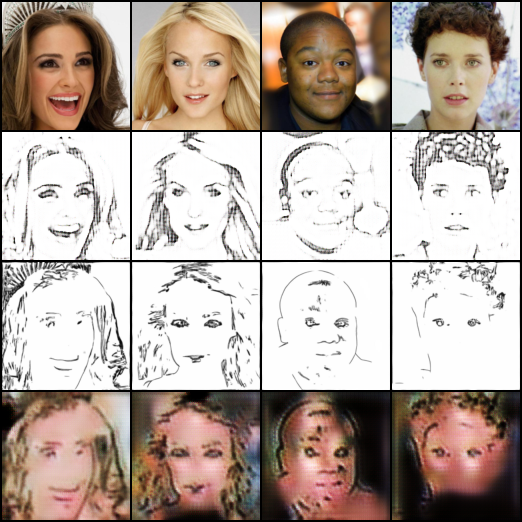

lr1e-4_bs1


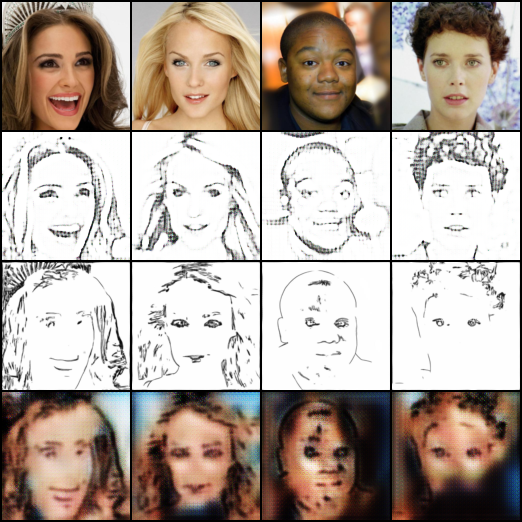

lr2e-4_bs4


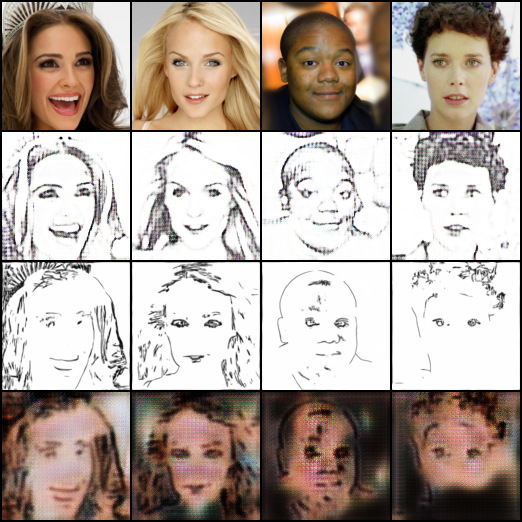

In [10]:
import glob
from IPython.display import Image, display
for name in TUNE:
    print(name); display(Image(sorted(glob.glob(f"{CKPT}/tune_{name}/samples/epoch_*.png"))[-1]))

## 5. Full training
Uses the lr/batch size picked by the tuning step (`BEST_RUN`). To force a setting, replace the first line with e.g. `BEST = "--lr 2e-4 --batch_size 1"`.

**Session time:** the defaults below (256 px, 1,500 images per domain, 20 epochs) are sized so the whole notebook fits in one Colab session, roughly 2–3 hours on a T4. For better quality, raise `EPOCHS`/`MAX_SAMPLES` if your Colab plan allows longer sessions.

**Disconnects:** if Colab disconnects anyway, just **Run all** again. Finished tuning runs are skipped and training resumes from `latest.pth`.

**Drive space:** `latest.pth` is about 340 MB and every 5th epoch adds a 91 MB snapshot. Empty Drive's Trash now and then.

In [11]:
BEST = TUNE[BEST_RUN]
EPOCHS, MAX_SAMPLES, IMAGE_SIZE = 20, 1500, 256
!python -u train.py $DATA_FLAGS --checkpoint_dir "$CKPT/main" {BEST} --epochs {EPOCHS} --max_samples {MAX_SAMPLES} --image_size {IMAGE_SIZE} --snapshot_every 5 --amp --num_workers 2 2>&1 | tee -a "$CKPT/logs/train_main.log"
import os
assert os.path.exists(f"{CKPT}/main/latest.pth"), "training failed: see the output above"

2026-10-12 14:26:05,849 INFO photos=1500 sketches=1500 iters/epoch=1500 device=cuda
2026-10-12 14:26:31,260 INFO epoch 1 it 100/1500 loss_G=7.572 loss_D=0.859 loss_gan=1.008 loss_cycle=4.571 loss_idt=1.994
2026-10-12 14:26:57,261 INFO epoch 1 it 200/1500 loss_G=4.611 loss_D=0.520 loss_gan=0.824 loss_cycle=2.642 loss_idt=1.145
2026-10-12 14:27:22,837 INFO epoch 1 it 300/1500 loss_G=5.684 loss_D=0.493 loss_gan=0.735 loss_cycle=3.331 loss_idt=1.618
2026-10-12 14:27:47,509 INFO epoch 1 it 400/1500 loss_G=6.409 loss_D=0.573 loss_gan=0.856 loss_cycle=3.972 loss_idt=1.581
2026-10-12 14:28:12,608 INFO epoch 1 it 500/1500 loss_G=5.466 loss_D=0.549 loss_gan=0.616 loss_cycle=3.146 loss_idt=1.703
2026-10-12 14:28:37,820 INFO epoch 1 it 600/1500 loss_G=5.798 loss_D=0.481 loss_gan=0.634 loss_cycle=3.638 loss_idt=1.526
2026-10-12 14:29:02,739 INFO epoch 1 it 700/1500 loss_G=4.662 loss_D=0.369 loss_gan=0.665 loss_cycle=2.808 loss_idt=1.190
2026-10-12 14:29:27,766 INFO epoch 1 it 800/1500 loss_G=3.299 

### Full training log (all sessions)
Training usually spans several Colab sessions, and the cell above only keeps the last one. This prints every session's progress, with timestamps, from the log on Drive.

In [12]:
!cat "$CKPT/logs/train_main.log"

2026-10-12 14:26:05,849 INFO photos=1500 sketches=1500 iters/epoch=1500 device=cuda
2026-10-12 14:26:31,260 INFO epoch 1 it 100/1500 loss_G=7.572 loss_D=0.859 loss_gan=1.008 loss_cycle=4.571 loss_idt=1.994
2026-10-12 14:26:57,261 INFO epoch 1 it 200/1500 loss_G=4.611 loss_D=0.520 loss_gan=0.824 loss_cycle=2.642 loss_idt=1.145
2026-10-12 14:27:22,837 INFO epoch 1 it 300/1500 loss_G=5.684 loss_D=0.493 loss_gan=0.735 loss_cycle=3.331 loss_idt=1.618
2026-10-12 14:27:47,509 INFO epoch 1 it 400/1500 loss_G=6.409 loss_D=0.573 loss_gan=0.856 loss_cycle=3.972 loss_idt=1.581
2026-10-12 14:28:12,608 INFO epoch 1 it 500/1500 loss_G=5.466 loss_D=0.549 loss_gan=0.616 loss_cycle=3.146 loss_idt=1.703
2026-10-12 14:28:37,820 INFO epoch 1 it 600/1500 loss_G=5.798 loss_D=0.481 loss_gan=0.634 loss_cycle=3.638 loss_idt=1.526
2026-10-12 14:29:02,739 INFO epoch 1 it 700/1500 loss_G=4.662 loss_D=0.369 loss_gan=0.665 loss_cycle=2.808 loss_idt=1.190
2026-10-12 14:29:27,766 INFO epoch 1 it 800/1500 loss_G=3.299 

## 6. Monitor training

,epoch,loss_G,loss_D,loss_gan,loss_cycle,loss_idt,lr,seconds
15,16,2.9466,0.2878,0.9489,1.4742,0.5236,0.000045,374.4
16,17,2.8670,0.2844,0.9438,1.4205,0.5027,0.000036,374.4
17,18,2.7728,0.2835,0.9267,1.3643,0.4817,0.000027,374.5
18,19,2.6721,0.2945,0.8945,1.3118,0.4658,0.000018,374.0
19,20,2.5952,0.2898,0.8667,1.2761,0.4524,0.000009,374.2


/content/drive/MyDrive/cyclegan_ckpt/main/samples/epoch_020.png (rows: photo, ->sketch, sketch, ->photo)


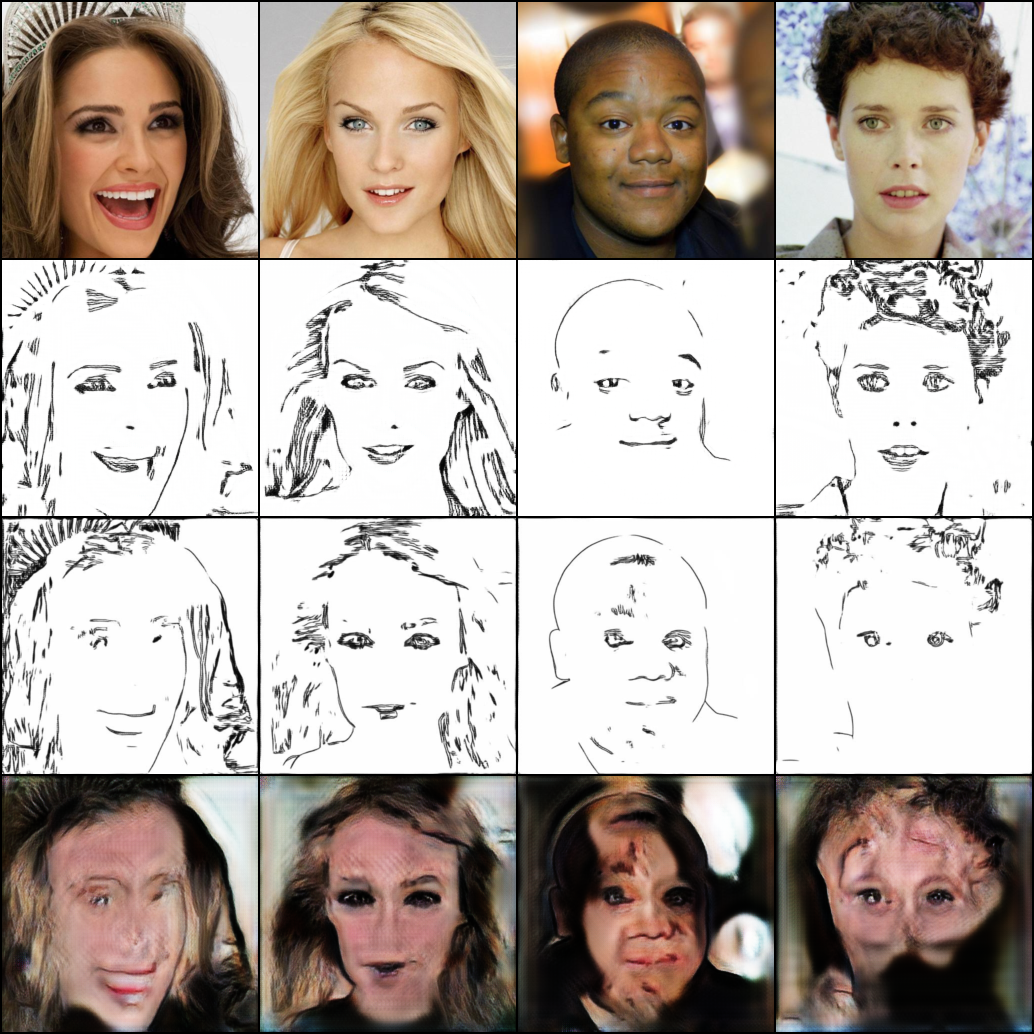

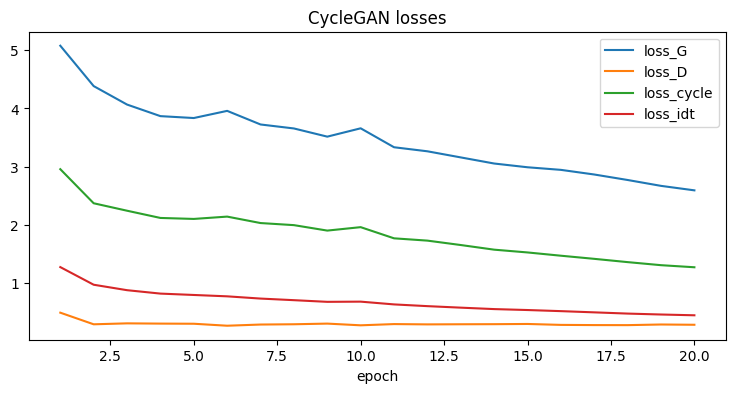

In [13]:
import glob
import pandas as pd
from IPython.display import Image, display
h = pd.read_csv(f"{CKPT}/main/history.csv")
h.plot(x="epoch", y=["loss_G", "loss_D", "loss_cycle", "loss_idt"], figsize=(9, 4), title="CycleGAN losses")
display(h.tail())
latest = sorted(glob.glob(f"{CKPT}/main/samples/epoch_*.png"))[-1]
print(latest, "(rows: photo, ->sketch, sketch, ->photo)"); display(Image(latest))

## 7. Test both directions
Uses the auto-detector: a photo becomes a sketch and a sketch becomes a photo.

photo2sketch: 10132.jpg -> /content/out_0.png


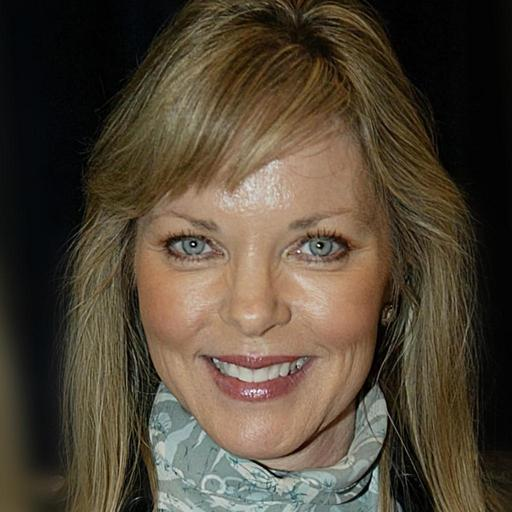

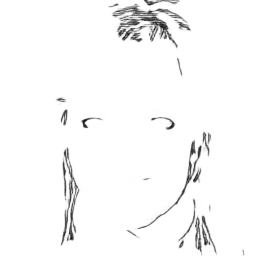

sketch2photo: 10132.jpg -> /content/out_1.png


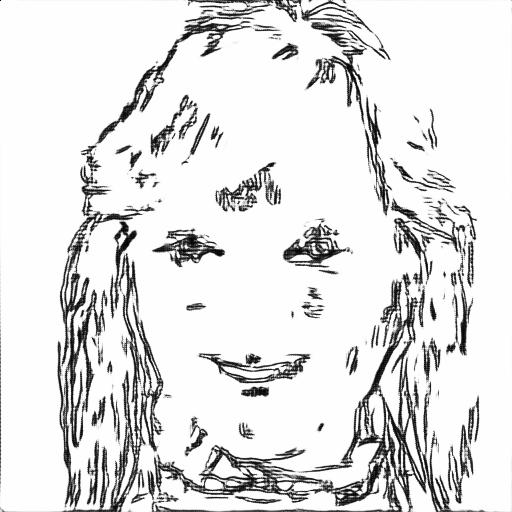

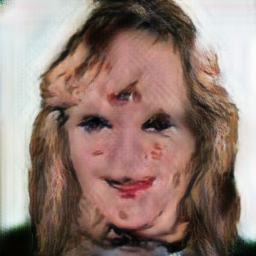

In [14]:
from IPython.display import Image, display
from dataset import resolve_domains
try:
    test_photos, test_sketches = resolve_domains(TEST_ROOT)
except (TypeError, FileNotFoundError, ValueError) as err:  # no test split, or its folders aren't auto-detectable
    print(f"WARNING: using training images for this test ({err}); results may be optimistic")
    test_photos, test_sketches = train_photos, train_sketches
for i, src in enumerate([test_photos[0], test_sketches[0]]):
    !python -u inference.py --checkpoint "$CKPT/main/latest.pth" --input "{src}" --output /content/out_{i}.png 2>&1 | tee -a "$CKPT/logs/inference.log"
    display(Image(str(src), width=256), Image(f"/content/out_{i}.png", width=256))

### Sketch/photo auto-detection accuracy
The UI picks the direction with `inference.is_sketch`. This measures how often it is right on held-out images. Report the number.

In [15]:
import random
from PIL import Image as PILImage
from inference import is_sketch
rng = random.Random(0)
P, S = rng.sample(test_photos, min(500, len(test_photos))), rng.sample(test_sketches, min(500, len(test_sketches)))
photo_ok = sum(not is_sketch(PILImage.open(p)) for p in P)
sketch_ok = sum(is_sketch(PILImage.open(p)) for p in S)
print(f"photos correctly detected:   {photo_ok}/{len(P)}")
print(f"sketches correctly detected: {sketch_ok}/{len(S)}")
print(f"overall accuracy: {(photo_ok + sketch_ok) / (len(P) + len(S)):.1%}")

photos correctly detected:   498/500
sketches correctly detected: 500/500
overall accuracy: 99.8%


## 8. Export the model for the local UI
Saves only the two generators from the latest epoch (about 91 MB) as `cyclegan_final.pth`, then downloads it. Put the file in `q2/checkpoints/` on your computer and run `./run_local.sh`. See *Run the UI locally* in the README.

In [16]:
import torch
state = torch.load(f"{CKPT}/main/latest.pth", map_location="cpu", weights_only=False)
torch.save({k: state[k] for k in ("epoch", "args", "G_AB", "G_BA")}, f"{CKPT}/cyclegan_final.pth")
print(f"exported epoch {state['epoch']} -> {CKPT}/cyclegan_final.pth")
from google.colab import files; files.download(f"{CKPT}/cyclegan_final.pth")  # or grab it from Drive

exported epoch 20 -> /content/drive/MyDrive/cyclegan_ckpt/cyclegan_final.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Before closing the session
Flush Drive so the last checkpoint is fully written.

In [17]:
from google.colab import drive; drive.flush_and_unmount()